# Klasterisasi Puskesmas Berdasarkan Indikator Stunting Menggunakan K-Means sebagai Pendukung Penentuan Wilayah Prioritas Penanganan di Dinas Kesehatan Kota Padang

> **Cerita Utama Proyek Ini (3 Kalimat):**
> 1. Data BNBA dibersihkan, lalu diringkas jadi 5 angka per puskesmas.
> 2. K-Means (K=3) mengelompokkan 24 puskesmas, lalu kelompok diberi nama prioritas.
> 3. Hasil diuji dengan 4 cara dan disimpulkan jujur: pola ada tapi lemah.

Rumusan Masalah: Puskesmas mana yang sebaiknya diprioritaskan Dinas Kesehatan untuk penanganan stunting, dan seperti apa profil masalahnya?

| # | Tahap | Isinya dalam Satu Kalimat |
|---|---|---|
| 1 | Problem Definition | Menetapkan tujuan penentuan wilayah prioritas stunting untuk Dinas Kesehatan Kota Padang. |
| 2 | Data Collection | Memuat 3 file BNBA (Maret-Mei 2026) dan data sasaran balita dari Dinkes. |
| 3 | EDA | Memeriksa kualitas data mentah dan perbedaan volume pelaporan antarpuskesmas. |
| 4 | Data Preprocessing | Membersihkan data anomali (tanggal, usia > 60 bulan, dan ketidakkonsistenan status gizi). |
| 5 | Feature Engineering & Selection | Meringkas data anak menjadi 5 indikator utama per puskesmas dan menstandardisasinya. |
| 6 | Data Splitting | Menguji apakah pola Maret-April tetap konsisten saat diterapkan pada bulan Mei. |
| 7 | Model Selection | Memilih K-Means karena menghasilkan kelompok seimbang dan pusat kelompok yang mudah dibaca. |
| 8 | Model Training | Melatih model K-Means (K=3) dan menetapkan nama prioritas berdasarkan skor urgensi. |
| 9 | Hyperparameter Tuning | Memilih K=3 sesuai kebutuhan tiga tingkat prioritas kebijakan Dinas Kesehatan. |
| 10 | Model Evaluation | Menguji hasil dengan 4 cara (lawan acak, antarbulan, sampel anak, dan kepekaan fitur). |
| 11 | Finalisasi Model | Menyimpan model final .pkl, metadata batasan, dan tabel luaran Excel untuk aplikasi web. |
| 12 | Deployment & Monitoring | Menyediakan fungsi siap pakai untuk memproses data bulan baru dan memantau pergeseran indikator. |

**Pembagian kerja:**
- Dhyva = Tahap 1-5
- Madani = Tahap 6-9 dan validasi Tahap 10
- Aqila = Visualisasi Tahap 10 dan Tahap 11-12.


In [ ]:
# ==== SEL 1: PERSIAPAN (jalankan sekali di awal) ====
import os, glob, json, datetime, zipfile, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from scipy.stats import spearmanr
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.mixture import GaussianMixture
from sklearn.decomposition import PCA
from sklearn.pipeline import Pipeline
from sklearn.metrics import (silhouette_score, silhouette_samples, davies_bouldin_score,
                             calinski_harabasz_score, adjusted_rand_score)
try:
    from IPython.display import display      # tersedia di Google Colab / Jupyter
except ImportError:
    display = print

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid')
pd.set_option('display.width', 250)
pd.set_option('display.max_columns', 40)

# ---- Pengaturan utama (ubah di sini saja) ----
SEED = 42                      # angka awal pengacak: seed sama = hasil sama
K = 3                          # jumlah kelompok (3 tingkat prioritas Dinkes)
N_INIT = 30                    # disamakan ke 30 di semua tempat (stabil dan cepat)
BULAN = ['2026-03', '2026-04', '2026-05']
BULAN_LATIH = ['2026-03', '2026-04']   # data latih untuk uji Tahap 6
BULAN_UJI = '2026-05'                  # data uji untuk Tahap 6
BUANG_USIA_DI_ATAS_60_BULAN = True     # BNBA untuk balita 0-59 bulan; False = pertahankan baris usia > 60 bulan

# 5 Indikator Utama (nama ringkas dan mudah dibaca)
fitur_klaster = [
    'Kasus per sasaran balita',
    'Persen sangat pendek',
    'Persen stunting + kurus',
    'Persen berat tidak naik',
    'Persen bumil KEK'
]

print("Persiapan selesai.")


## Tahap 1 - Problem Definition (Merumuskan Masalah)

**Masalah.** Penanganan stunting (makanan bergizi, pemantauan, dll.) pada dasarnya sama untuk setiap anak. Yang bisa diputuskan berbeda adalah **wilayah mana yang didahulukan**. Karena itu yang dikelompokkan adalah wilayah, bukan anak.

**Unit analisis.** 24 puskesmas Kota Padang, lalu hasilnya dirangkum per **11 kecamatan** (sesuai arahan dosen). Puskesmas dipakai karena 11 kecamatan terlalu sedikit untuk dikelompokkan.

**Jenis tugas.** *Unsupervised learning* (klasterisasi): tidak ada label benar/salah, jadi tidak ada "akurasi". Mutu hasil dinilai dari skor internal, kestabilan, dan kemudahan dibaca.

**Pertanyaan yang dijawab**
1. Puskesmas atau kecamatan mana yang masuk kelompok prioritas, dan apa cirinya?
2. Seberapa stabil kelompok itu terhadap perubahan bulan, sampel, dan pilihan desain?

**Kriteria keberhasilan** (diperiksa di Tahap 10): tiap kelompok minimal 3 puskesmas dan bisa diberi nama dari ciri-cirinya; skor dilaporkan apa adanya; kestabilan diuji; luaran siap pakai (tabel, model `.pkl`, aplikasi web).

**Pengguna:** Dinas Kesehatan Kota Padang dan kepala puskesmas.

**Batasan yang diakui sejak awal**
- Data hanya **3 bulan**. Hasilnya potret, bukan tren. Tren butuh data minimal 1 tahun.
- BNBA hanya berisi balita yang **sudah tercatat stunting**, jadi indikator ini adalah *kasus tercatat per sasaran balita (%)*, bukan prevalensi sebenarnya di seluruh populasi.
- Tidak ada data karangan. Semua dari 3 file BNBA asli dan rekap Dinkes.
- Kemiskinan, sanitasi, dan air bersih tidak dimasukkan karena tidak ada data resmi per puskesmas. Kalau tersedia, tambahkan sebagai fitur di Tahap 5.


## Tahap 2 - Data Collection (Mengumpulkan Data)


**Sumber data**
1. BNBA Balita Stunting Maret, April, Mei 2026 (data per anak).
2. Rekap Dinkes per puskesmas: **sasaran balita** dan **% ibu hamil KEK** (dimasukkan di Tahap 5).

In [2]:
# ==== SEL 2: MEMUAT 3 FILE BNBA ====
def ada_file_bnba():
    return all(any('bnba' in f.lower() and kata in f.lower() for f in glob.glob('*.xlsx'))
               for kata in ('maret', 'april', 'mei'))

if not ada_file_bnba():                       # di Colab: minta unggah file bila belum ada
    try:
        from google.colab import files
        print("File BNBA belum ada. Pilih 3 file BNBA (Maret, April, Mei):")
        files.upload()
    except ImportError:
        pass

def cari_file(kata):
    hasil = [f for f in glob.glob('*.xlsx') if 'bnba' in f.lower() and kata in f.lower()]
    if len(hasil) != 1:
        raise FileNotFoundError(f"Harus ada tepat 1 file BNBA '{kata}' di folder kerja, ditemukan: {hasil}")
    return hasil[0]

file_bulan = {'2026-03': cari_file('maret'), '2026-04': cari_file('april'), '2026-05': cari_file('mei')}

# Pembersihan memakai ISI DATA (bukan nomor baris):
#   a) buang blok yang kolomnya bergeser (Kab/Kota bukan 'KOTA PADANG')
#   b) buang baris yang tanggal ukurnya bukan bulan file tersebut (salinan bulan lain / salah ketik tahun)
def muat_bulan(path, bulan, verbose=True):
    xls = pd.ExcelFile(path)
    sheet = 'Application List' if 'Application List' in xls.sheet_names else xls.sheet_names[0]
    df = pd.read_excel(xls, sheet_name=sheet)
    df = df.drop(columns=['Nama Ortu', 'No'], errors='ignore')      # samakan susunan kolom
    mentah = len(df)
    df['Tanggal Pengukuran'] = pd.to_datetime(df['Tanggal Pengukuran'], errors='coerce')
    df = df[df['Kab/Kota'].astype(str).str.strip().str.upper() == 'KOTA PADANG']
    n_geser = mentah - len(df)
    df = df[df['Tanggal Pengukuran'].dt.strftime('%Y-%m') == bulan]
    n_bulan_lain = mentah - n_geser - len(df)
    df = df.copy()
    df['Bulan'] = bulan
    if verbose:
        print(f"[{bulan}] baris mentah {mentah} | blok bergeser dibuang {n_geser} | beda bulan dibuang {n_bulan_lain} | dipakai {len(df)}")
    return df

df_gabungan = pd.concat([muat_bulan(p, b) for b, p in file_bulan.items()], ignore_index=True)
print(f"\nTotal gabungan 3 bulan (belum dibersihkan nilainya): {len(df_gabungan)} baris, {df_gabungan.shape[1]} kolom")
display(df_gabungan.groupby('Bulan').size().rename('Jumlah_baris').to_frame())
display(df_gabungan.head(3))


[2026-03] baris mentah 1472 | blok bergeser dibuang 0 | beda bulan dibuang 1 | dipakai 1471
[2026-04] baris mentah 1487 | blok bergeser dibuang 0 | beda bulan dibuang 0 | dipakai 1487
[2026-05] baris mentah 4604 | blok bergeser dibuang 1472 | beda bulan dibuang 1487 | dipakai 1645

Total gabungan 3 bulan (belum dibersihkan nilainya): 4603 baris, 23 kolom


,Jumlah_baris
Bulan,
2026-03,1471
2026-04,1487
2026-05,1645


,NIK,Nama,JK,Tgl Lahir,Prov,Kab/Kota,Kec,Pukesmas,Desa/Kel,Posyandu,Tanggal Pengukuran,Berat,Tinggi,BB/U,ZS BB/U,TB/U,ZS TB/U,BB/TB,ZS BB/TB,Naik Berat Badan,PMT Aktif,Tindakan,Bulan
0,3758223194,MUHAMMAD KENZO,L,2023-11-25,SUMATERA BARAT,KOTA PADANG,NANGGALO,NANGGALO,KURAO PAGANG,melati,2026-03-09,9.0,78.0,Sangat Kurang,-3.06,Sangat Pendek,-3.67,Gizi Baik,-1.55,T,-,NaN,2026-03
1,910249840,RAFAZA,L,2024-08-21,SUMATERA BARAT,KOTA PADANG,KURANJI,KURANJI,KALUMBUK,KP.MARAPAK,2026-03-09,9.5,76.5,Normal,-1.36,Pendek,-2.31,Gizi Baik,-0.38,T,-,NaN,2026-03
2,1271062207220000,AZLAN JUHENDRA,L,2022-07-22,SUMATERA BARAT,KOTA PADANG,LUBUK BEGALUNG,LUBUK BEGALUNG,KAMPUNG BARU NAN XX,FLAMBOYAN V,2026-03-05,10.6,88.5,Sangat Kurang,-3.13,Sangat Pendek,-3.04,Gizi Kurang,-2.14,N,-,NaN,2026-03


## Tahap 3 - EDA (Memeriksa Data)

Tahap Exploratory Data Analysis (EDA) dilakukan untuk memeriksa kualitas data mentah sebelum masuk ke tahap pengolahan lanjutan. Pada tahap ini, kita mengecek jumlah baris, sebaran data, serta mengidentifikasi adanya nilai-nilai ekstrem atau anomali yang perlu dibersihkan pada Tahap 4.

In [3]:
# Salinan khusus EDA (data asli df_gabungan tidak diubah)
eda = df_gabungan.copy()
for col in ['Berat', 'Tinggi', 'ZS BB/U', 'ZS TB/U', 'ZS BB/TB']:
    eda[col] = pd.to_numeric(eda[col], errors='coerce')
eda['Tgl Lahir'] = pd.to_datetime(eda['Tgl Lahir'], errors='coerce')
eda['Usia_Bulan'] = ((eda['Tanggal Pengukuran'] - eda['Tgl Lahir']).dt.days / 30.4375).round(2)
for col_w in ['Kec', 'Pukesmas', 'Desa/Kel']:
    eda[col_w] = eda[col_w].astype(str).str.strip().str.upper()

print(f"Baris: {len(eda)} | Puskesmas: {eda['Pukesmas'].nunique()} | Kecamatan: {eda['Kec'].nunique()} | Kelurahan: {eda['Desa/Kel'].nunique()}")
miss = eda.isna().mean().mul(100).round(1)
print("\nKolom dengan nilai kosong (%):")
display(miss[miss > 0].sort_values(ascending=False).to_frame('Kosong (%)'))
print("Ringkasan statistik kolom numerik:")
display(eda[['Usia_Bulan', 'Berat', 'Tinggi', 'ZS BB/U', 'ZS TB/U', 'ZS BB/TB']].describe().round(2))


Baris: 4603 | Puskesmas: 24 | Kecamatan: 11 | Kelurahan: 103

Kolom dengan nilai kosong (%):


,Kosong (%)
Tindakan,32.0
Posyandu,0.2


Ringkasan statistik kolom numerik:


,Usia_Bulan,Berat,Tinggi,ZS BB/U,ZS TB/U,ZS BB/TB
count,4603.00,4603.00,4603.00,4603.00,4603.00,4603.00
mean,31.50,11.59,80.70,0.60,-2.71,8.12
std,16.91,55.24,13.22,96.27,0.67,142.31
min,0.00,1.20,39.00,-5.81,-5.96,-6.14
25%,19.04,8.20,74.00,-2.75,-2.97,-1.68
50%,32.95,10.40,83.60,-2.17,-2.52,-0.92
75%,45.48,12.00,90.50,-1.57,-2.22,0.05
max,60.98,2400.00,101.00,4259.47,-2.01,7777.15


,Jumlah baris
|Z-score| > 10,37
Berat > 35 kg,6
Berat > 100 (kemungkinan satuan gram),4
Usia <= 0 bulan atau kosong,91
Usia > 60 bulan,33


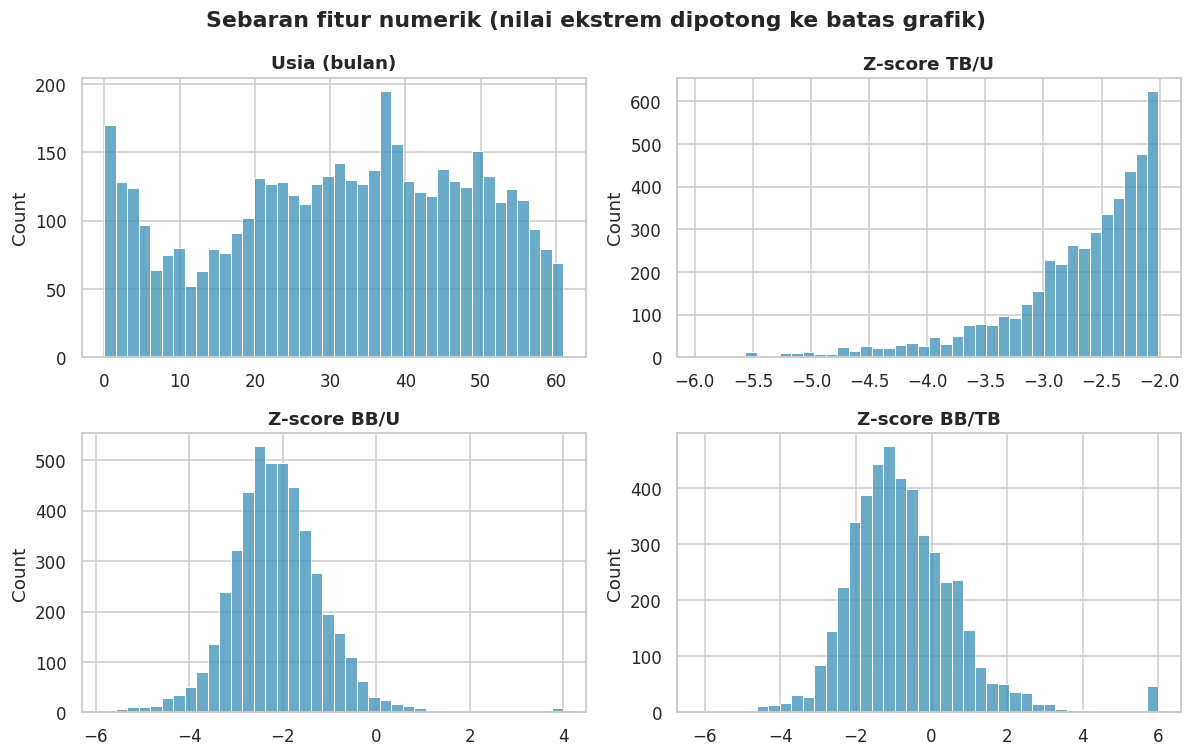

In [4]:
# Indikasi nilai tidak wajar (yang akan ditangani di Tahap 4)
anomali = pd.Series({
    '|Z-score| > 10': int((eda[['ZS BB/U', 'ZS TB/U', 'ZS BB/TB']].abs() > 10).any(axis=1).sum()),
    'Berat > 35 kg': int((eda['Berat'] > 35).sum()),
    'Berat > 100 (kemungkinan satuan gram)': int((eda['Berat'] > 100).sum()),
    'Usia <= 0 bulan atau kosong': int(((eda['Usia_Bulan'] <= 0) | eda['Usia_Bulan'].isna()).sum()),
    'Usia > 60 bulan': int((eda['Usia_Bulan'] > 60).sum()),
}).to_frame('Jumlah baris')
display(anomali)

fig, ax = plt.subplots(2, 2, figsize=(11, 7), dpi=110)
for a, (col, rng, ttl) in zip(ax.ravel(), [
        ('Usia_Bulan', (0, 70), 'Usia (bulan)'), ('ZS TB/U', (-8, 4), 'Z-score TB/U'),
        ('ZS BB/U', (-8, 4), 'Z-score BB/U'), ('ZS BB/TB', (-8, 6), 'Z-score BB/TB')]):
    sns.histplot(eda[col].dropna().clip(*rng), bins=40, color='#3a8fb7', ax=a)
    a.set_title(ttl, fontweight='bold'); a.set_xlabel('')
fig.suptitle('Sebaran fitur numerik (nilai ekstrem dipotong ke batas grafik)', fontweight='bold')
plt.tight_layout(); plt.show()


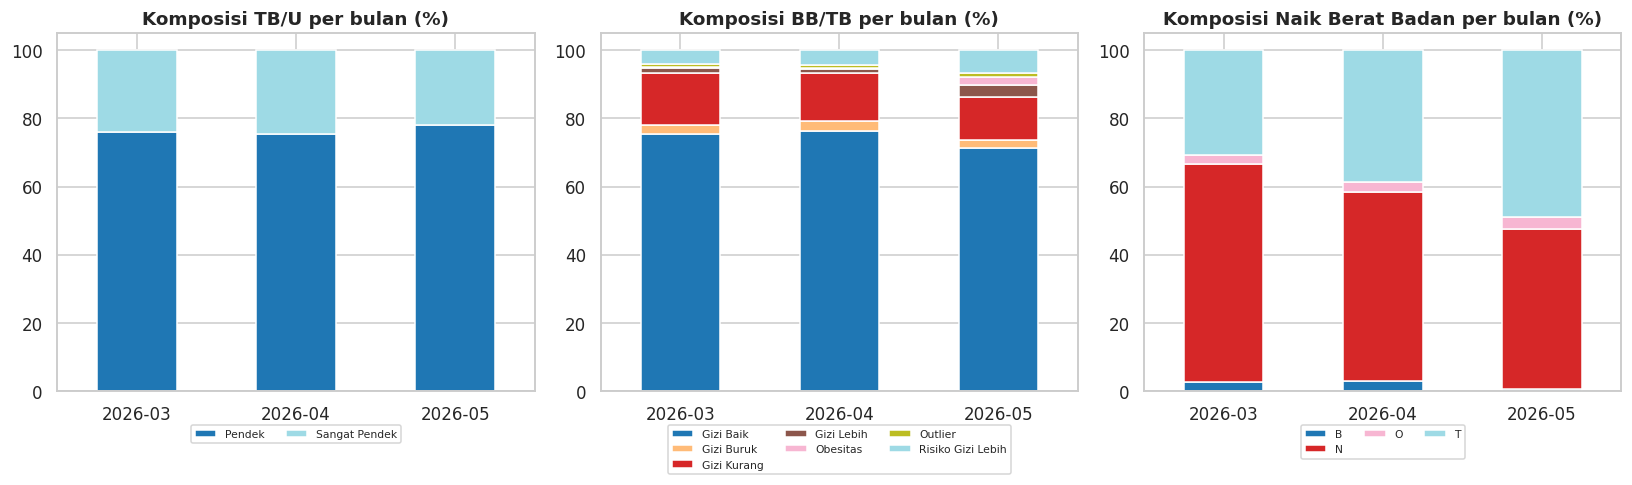

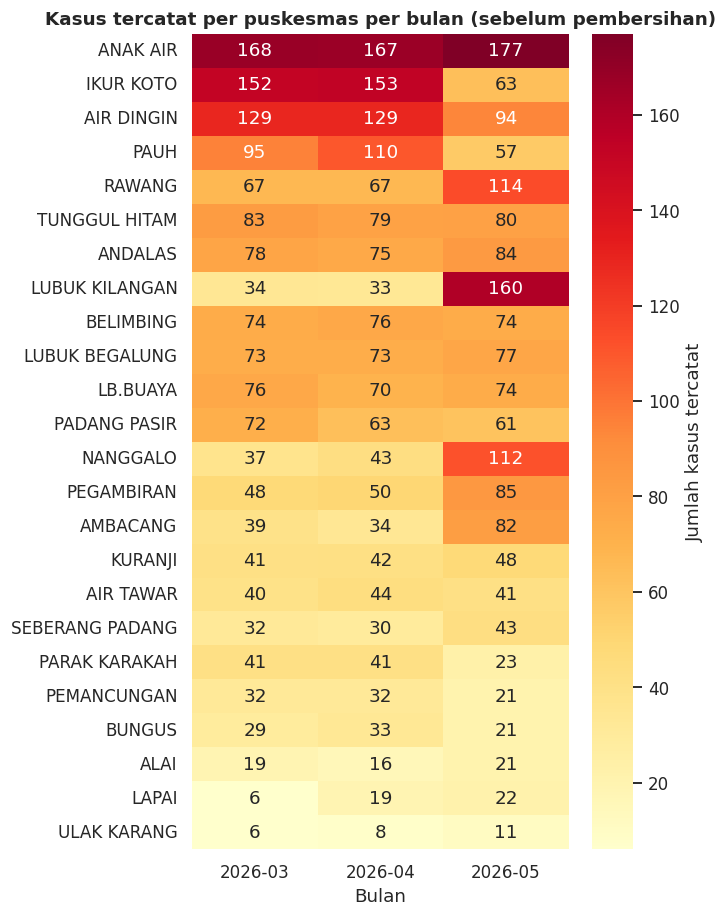

Total baris per bulan: {'2026-03': 1471, '2026-04': 1487, '2026-05': 1645}


In [5]:
# Komposisi status gizi per bulan + volume pelaporan per bulan
fig, ax = plt.subplots(1, 3, figsize=(15, 4.6), dpi=110)
for a, col in zip(ax, ['TB/U', 'BB/TB', 'Naik Berat Badan']):
    tab = pd.crosstab(eda['Bulan'], eda[col].astype(str).str.strip(), normalize='index') * 100
    tab.plot(kind='bar', stacked=True, ax=a, colormap='tab20', edgecolor='white')
    a.set_title(f'Komposisi {col} per bulan (%)', fontweight='bold'); a.set_xlabel(''); a.legend(fontsize=7, loc='upper center', bbox_to_anchor=(0.5, -0.08), ncol=3)
    a.tick_params(axis='x', rotation=0)
plt.tight_layout(); plt.show()

pivot = eda.pivot_table(index='Pukesmas', columns='Bulan', values='Nama', aggfunc='count').fillna(0).astype(int)
pivot = pivot.loc[pivot.sum(axis=1).sort_values(ascending=False).index]
plt.figure(figsize=(6.5, 8.5), dpi=110)
sns.heatmap(pivot, annot=True, fmt='d', cmap='YlOrRd', cbar_kws={'label': 'Jumlah kasus tercatat'})
plt.title('Kasus tercatat per puskesmas per bulan (sebelum pembersihan)', fontweight='bold'); plt.ylabel('')
plt.tight_layout(); plt.show()
print("Total baris per bulan:", pivot.sum().to_dict())


In [ ]:
# TEMUAN EDA - ditulis otomatis dari data yang baru dimuat (tidak ada angka tulisan tangan)
print("TEMUAN EDA (dasar keputusan di Tahap 4-6)\n")
print("1. Baris tidak wajar yang akan dibersihkan di Tahap 4:")
for k, v in anomali['Jumlah baris'].items(): print(f"   - {k}: {v} baris")
vol = pivot.sum()
print("\n2. Jumlah kasus tercatat tiap bulan: " + ", ".join(f"{b}: {int(v)}" for b, v in vol.items()))
if len(vol) > 1:
    arah = "lebih banyak" if vol.iloc[-1] > vol.iloc[:-1].mean() else "lebih sedikit"
    print(f"   Bulan terakhir {arah} dari rata-rata bulan sebelumnya ({vol.iloc[-1]:.0f} dibanding {vol.iloc[:-1].mean():.0f}).")
bbt = pd.crosstab(eda['Bulan'], eda['Naik Berat Badan'].astype(str).str.strip(), normalize='index') * 100
if 'T' in bbt.columns:
    print("   Persentase anak yang berat badannya tidak naik ('T') per bulan: " + ", ".join(f"{b}: {v:.1f}%" for b, v in bbt['T'].items()))
rasio = (pivot.max(axis=1) / pivot.replace(0, np.nan).min(axis=1)).sort_values(ascending=False).head(3)
print("\n3. Puskesmas yang jumlah kasusnya paling berubah antarbulan (terbesar dibanding terkecil):")
for p, r in rasio.items(): print(f"   - {p}: {' -> '.join(str(int(x)) for x in pivot.loc[p])}  (x{r:.1f})")
print("   Lonjakan sebesar ini bisa karena laporan yang makin lengkap, bukan karena kasus benar-benar naik (perlu konfirmasi Dinkes).")
print("   Karena itu pengelompokan memakai rata-rata 3 bulan, dan kestabilan antarbulan diuji di Tahap 6 dan 10.")
semua_stunting = (pd.to_numeric(eda['ZS TB/U'], errors='coerce') < -2).mean() * 100
print(f"\n4. Balita dengan Z-score TB/U di bawah -2: {semua_stunting:.1f}% dari semua baris.")
if semua_stunting > 95: print("   Hampir semua baris memang sudah stunting, jadi data ini tidak bisa dipakai menghitung prevalensi sebenarnya di populasi.")
print("\n5. Jumlah kasus antarpuskesmas sangat berbeda, jadi angka mentah dibagi sasaran balita (menjadi 'Kasus per sasaran balita').")


TEMUAN EDA (dasar keputusan di Tahap 4-6)

1. Baris tidak wajar yang akan dibersihkan di Tahap 4:
   - |Z-score| > 10: 37 baris
   - Berat > 35 kg: 6 baris
   - Berat > 100 (kemungkinan satuan gram): 4 baris
   - Usia <= 0 bulan atau kosong: 91 baris
   - Usia > 60 bulan: 33 baris

2. Jumlah kasus tercatat tiap bulan: 2026-03: 1471, 2026-04: 1487, 2026-05: 1645
   Bulan terakhir lebih banyak dari rata-rata bulan sebelumnya (1645 dibanding 1479).
   Persentase anak yang berat badannya tidak naik ('T') per bulan: 2026-03: 30.8%, 2026-04: 38.7%, 2026-05: 48.9%

3. Puskesmas yang jumlah kasusnya paling berubah antarbulan (terbesar dibanding terkecil):
   - LUBUK KILANGAN: 34 -> 33 -> 160  (x4.8)
   - LAPAI: 6 -> 19 -> 22  (x3.7)
   - NANGGALO: 37 -> 43 -> 112  (x3.0)
   Lonjakan sebesar ini bisa karena laporan yang makin lengkap, bukan karena kasus benar-benar naik (perlu konfirmasi Dinkes).
   Karena itu pengelompokan memakai rata-rata 3 bulan, dan kestabilan antarbulan diuji di Tahap 6 d

## Tahap 4 - Data Preprocessing (Membersihkan Data)

Tahap ini bertujuan memastikan kualitas data sebelum masuk ke proses agregasi, karena kesalahan input seperti satuan berat dalam gram atau pencatatan ganda dapat menggeser nilai rata-rata puskesmas.

**Langkahnya:**
1. ubah tipe data dan hitung usia,
2. koreksi berat yang salah satuan,
3. buang baris tidak wajar,
4. rapikan nama wilayah,
5. buat kunci anak dari nama + tanggal lahir (NIK tidak dipakai karena banyak yang tidak valid dan berubah antarbulan),
6. satu anak dihitung satu kali per bulan.

In [7]:
# ==== SEL: PEMBERSIHAN DATA ====
def bersihkan_data(df, buang_usia_60=BUANG_USIA_DI_ATAS_60_BULAN, verbose=True):
    d = df.copy()
    for col in ['Berat', 'Tinggi', 'ZS BB/U', 'ZS TB/U', 'ZS BB/TB']:
        d[col] = pd.to_numeric(d[col], errors='coerce')
    d['Tgl Lahir'] = pd.to_datetime(d['Tgl Lahir'], errors='coerce')
    d['Usia_Bulan'] = ((d['Tanggal Pengukuran'] - d['Tgl Lahir']).dt.days / 30.4375).round(2)

    # Salah ketik berat dalam gram (> 100 dibagi 1000)
    jml_salah_gram = int((d['Berat'] > 100).sum())
    d.loc[d['Berat'] > 100, 'Berat'] /= 1000.0

    zs = d[['ZS BB/U', 'ZS TB/U', 'ZS BB/TB']]
    alasan = pd.DataFrame({
        'Z-score tidak wajar atau kosong': (zs.abs() > 10).any(axis=1) | zs.isna().any(axis=1),
        'Berat > 35 kg': d['Berat'] > 35,
        'Usia <= 0 atau kosong (tgl lahir = tgl ukur)': (d['Usia_Bulan'] <= 0) | d['Usia_Bulan'].isna(),
        'Usia > 60 bulan (di luar balita)': (d['Usia_Bulan'] > 60) if buang_usia_60 else False,
    })
    mask_outlier = alasan.any(axis=1)
    if verbose:
        print("Rincian baris yang dibuang (satu baris bisa kena lebih dari satu alasan):")
        print(alasan.sum().to_string())
    d = d[~mask_outlier].copy()
    if verbose:
        print(f"Berat dikoreksi dari gram: {jml_salah_gram} baris | Dibuang: {int(mask_outlier.sum())} baris | Sisa valid: {len(d)} baris")

    # Rapikan nama wilayah; kunci anak = nama + tanggal lahir (NIK tidak dipakai: banyak tidak valid dan berubah antarbulan)
    for col_w in ['Kec', 'Pukesmas', 'Desa/Kel']:
        d[col_w] = d[col_w].astype(str).str.strip().str.upper()
    d['Kunci_Anak'] = d['Nama'].astype(str).str.strip().str.upper() + "_" + d['Tgl Lahir'].dt.strftime('%Y-%m-%d')

    # Satu anak hanya dihitung 1x per bulan (ambil pengukuran terakhir)
    n_sebelum = len(d)
    d = d.sort_values('Tanggal Pengukuran').drop_duplicates(['Bulan', 'Kunci_Anak'], keep='last')
    if verbose:
        print(f"Duplikat anak dalam bulan yang sama dibuang: {n_sebelum - len(d)} baris")
        print(f"Total baris akhir: {len(d)} | Anak unik lintas bulan: {d['Kunci_Anak'].nunique()}")
    return d

df_bersih = bersihkan_data(df_gabungan)


Rincian baris yang dibuang (satu baris bisa kena lebih dari satu alasan):
Z-score tidak wajar atau kosong                 37
Berat > 35 kg                                    2
Usia <= 0 atau kosong (tgl lahir = tgl ukur)    91
Usia > 60 bulan (di luar balita)                33
Berat dikoreksi dari gram: 4 baris | Dibuang: 130 baris | Sisa valid: 4473 baris
Duplikat anak dalam bulan yang sama dibuang: 2 baris
Total baris akhir: 4471 | Anak unik lintas bulan: 2417


## Tahap 5 - Feature Engineering & Selection (Membuat dan Memilih Fitur)

Data individu balita diagregasi menjadi 24 baris data puskesmas. Setiap puskesmas direpresentasikan oleh 5 indikator utama:

| Fitur | Cara hitung | Arti dalam satu kalimat |
|---|---|---|
| `Kasus per sasaran balita` | kasus tercatat / (sasaran balita x jumlah bulan) x 100 | Banyaknya kasus stunting yang tercatat dibanding total sasaran balita (%) |
| `Persen sangat pendek` | balita sangat pendek / kasus x 100 | Proporsi balita berstatus sangat pendek di antara kasus tercatat (%) |
| `Persen stunting + kurus` | gizi kurang atau buruk / kasus x 100 | Proporsi balita yang stunting sekaligus kurus / wasting (%) |
| `Persen berat tidak naik` | berat badan tidak naik (T) / kasus x 100 | Proporsi balita yang pertumbuhannya mandek / tidak naik (%) |
| `Persen bumil KEK` | % ibu hamil KEK (rekap resmi Dinkes) | Persentase ibu hamil kurang energi kronis di wilayah puskesmas (%) |

Semua fitur dibaca **makin tinggi = makin buruk / makin butuh perhatian**. Kemiskinan, sanitasi, dan air bersih sengaja tidak dipakai karena tidak ada data resmi per puskesmas.


In [8]:
# Data referensi sasaran balita & bumil KEK per puskesmas (rekap Dinkes Kota Padang)
sasaran_dict = {
    'IKUR KOTO': 1194, 'ANAK AIR': 2106, 'RAWANG': 1186, 'AIR TAWAR': 651,
    'SEBERANG PADANG': 643, 'PADANG PASIR': 1446, 'NANGGALO': 1740, 'LUBUK KILANGAN': 4276,
    'BUNGUS': 1872, 'ALAI': 2107, 'AIR DINGIN': 3234, 'TUNGGUL HITAM': 2423,
    'PAUH': 3136, 'PARAK KARAKAH': 1398, 'ANDALAS': 3261, 'PEMANCUNGAN': 1237,
    'AMBACANG': 2345, 'BELIMBING': 3653, 'KURANJI': 2126, 'LUBUK BEGALUNG': 4483,
    'LAPAI': 986, 'LB.BUAYA': 5818, 'PEGAMBIRAN': 5251, 'ULAK KARANG': 934
}
bumil_kek_dict = {
    'IKUR KOTO': 15.7, 'ANAK AIR': 11.6, 'RAWANG': 12.0, 'AIR TAWAR': 9.9,
    'SEBERANG PADANG': 16.4, 'PADANG PASIR': 12.2, 'NANGGALO': 11.7, 'LUBUK KILANGAN': 11.7,
    'BUNGUS': 16.2, 'ALAI': 25.4, 'AIR DINGIN': 9.6, 'TUNGGUL HITAM': 7.2,
    'PAUH': 13.4, 'PARAK KARAKAH': 10.6, 'ANDALAS': 11.3, 'PEMANCUNGAN': 10.4,
    'AMBACANG': 10.7, 'BELIMBING': 10.2, 'KURANJI': 10.9, 'LUBUK BEGALUNG': 9.2,
    'LAPAI': 8.5, 'LB.BUAYA': 2.9, 'PEGAMBIRAN': 11.2, 'ULAK KARANG': 9.7
}
tak_cocok = set(df_bersih['Pukesmas']) - set(sasaran_dict)
assert not tak_cocok, f"Nama puskesmas tidak cocok dengan kamus sasaran: {tak_cocok}"
print(f"Puskesmas terdeteksi: {df_bersih['Pukesmas'].nunique()} (harus 24)")


Puskesmas terdeteksi: 24 (harus 24)


In [ ]:
# Fungsi agregasi (dipakai untuk per-bulan dan gabungan 3 bulan)
def hitung_fitur(grp, jml_bulan):
    out = grp.agg(
        Jml_kelurahan=('Desa/Kel', 'nunique'),
        Total_Kasus=('Kunci_Anak', 'count'),
        Total_SP=('TB/U', lambda s: (s.astype(str).str.strip() == 'Sangat Pendek').sum()),
        Total_SW=('BB/TB', lambda s: s.astype(str).str.strip().isin(['Gizi Kurang', 'Gizi Buruk']).sum()),
        Total_BBT=('Naik Berat Badan', lambda s: (s.astype(str).str.strip() == 'T').sum()),
    ).reset_index().rename(columns={'Kec': 'Kecamatan', 'Pukesmas': 'Puskesmas'})
    out['Rerata_kasus_per_bulan'] = (out['Total_Kasus'] / jml_bulan).round(1)
    out['Sasaran_balita_per_bulan'] = out['Puskesmas'].map(sasaran_dict)
    out['Kasus per sasaran balita'] = (out['Total_Kasus'] / (out['Sasaran_balita_per_bulan'] * jml_bulan) * 100).round(2)
    out['Persen sangat pendek'] = (out['Total_SP'] / out['Total_Kasus'] * 100).round(1)
    out['Persen stunting + kurus'] = (out['Total_SW'] / out['Total_Kasus'] * 100).round(1)
    out['Persen berat tidak naik'] = (out['Total_BBT'] / out['Total_Kasus'] * 100).round(1)
    out['Persen bumil KEK'] = out['Puskesmas'].map(bumil_kek_dict)
    return out

# Agregasi per puskesmas-bulan (untuk uji stabilitas antarbulan)
agg_bulanan = pd.concat(
    [hitung_fitur(sub.groupby(['Kec', 'Pukesmas']), 1).assign(Bulan=bln) for bln, sub in df_bersih.groupby('Bulan')],
    ignore_index=True)

# Gabungan 3 bulan per puskesmas (24 puskesmas) = basis pemodelan
df_puskesmas = hitung_fitur(df_bersih.groupby(['Kec', 'Pukesmas']), 3)
df_puskesmas = df_puskesmas.sort_values('Puskesmas').reset_index(drop=True)
assert df_puskesmas['Puskesmas'].nunique() == 24, f"Puskesmas terdeteksi {df_puskesmas['Puskesmas'].nunique()}, seharusnya 24"

# Standardisasi fitur (StandardScaler: mean=0, std=1)
X = df_puskesmas[fitur_klaster].copy()
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("=== 24 PUSKESMAS KOTA PADANG (5 INDIKATOR UTAMA) ===")
display(df_puskesmas.sort_values('Kasus per sasaran balita', ascending=False)[
    ['Puskesmas', 'Kecamatan', 'Rerata_kasus_per_bulan', 'Sasaran_balita_per_bulan'] + fitur_klaster])


In [ ]:
# Cek keterkaitan antarfitur (korelasi)
korelasi = df_puskesmas[fitur_klaster].corr().round(2)
plt.figure(figsize=(6, 4.5), dpi=110)
sns.heatmap(korelasi, annot=True, cmap='coolwarm', vmin=-1, vmax=1, fmt='.2f', cbar_kws={'shrink': 0.8})
plt.title('Korelasi Antarindikator (24 Puskesmas Kota Padang)', fontweight='bold')
plt.tight_layout()
plt.show()

pasangan = [(a, b, korelasi.loc[a, b]) for i, a in enumerate(fitur_klaster) for b in fitur_klaster[i+1:] if abs(korelasi.loc[a, b]) >= 0.7]
print("Seleksi Fitur: Kelima fitur dipertahankan karena mewakili dimensi berbeda (beban kasus, keparahan balita, pertumbuhan mandek, dan risiko ibu).")
print("Korelasi kuat (|r| >= 0.7):", pasangan if pasangan else "Tidak ada (tidak ada informasi ganda).")


In [ ]:
NAMA_P = {1: 'Prioritas 1 - Urgensi Tertinggi', 2: 'Prioritas 2 - Urgensi Menengah', 3: 'Prioritas 3 - Pemantauan Rutin'}
REKOMENDASI = {
    NAMA_P[1]: 'Usulan: percepatan intervensi (PMT lokal, sweeping penimbangan posyandu), verifikasi kelengkapan pelaporan, dan rujukan kasus balita sangat pendek.',
    NAMA_P[2]: 'Usulan: penanganan wilayah beban kasus tinggi (logistik pangan, pos gizi posyandu, serta intervensi Ibu Hamil KEK).',
    NAMA_P[3]: 'Usulan: pemantauan rutin bulanan di posyandu serta edukasi gizi dan sanitasi keluarga.'
}

def hitung_skor_urgensi(df_fitur, fts=fitur_klaster):
    """Menghitung skor urgensi komposit tiap baris (rata-rata z-score 5 fitur).
    Positif = di atas rata-rata Kota Padang = lebih butuh perhatian."""
    z = (df_fitur[fts] - df_fitur[fts].mean()) / df_fitur[fts].std(ddof=0)
    return z.mean(axis=1).round(2)

def beri_nama_prioritas(centroid_z_df):
    """Memberi label Prioritas 1 s.d. 3 berdasarkan urutan rata-rata skor urgensi klaster (tertinggi = Prioritas 1)."""
    urutan = centroid_z_df.mean(axis=1).sort_values(ascending=False).index
    return {int(c): NAMA_P[i + 1] for i, c in enumerate(urutan)}


## Tahap 6 - Data Splitting (Membagi Data)

Menguji apakah pola hubungan antarfitur pada data latih (Maret-April) tetap konsisten ketika diterapkan untuk mengelompokkan data uji (Mei).


In [ ]:
# Uji konsistensi: latih pada Maret-April, uji pada Mei
sub_latih = df_bersih[df_bersih['Bulan'].isin(BULAN_LATIH)]
df_latih = hitung_fitur(sub_latih.groupby(['Kec', 'Pukesmas']), 2).sort_values('Puskesmas')
scaler_latih = StandardScaler()
X_latih = scaler_latih.fit_transform(df_latih[fitur_klaster])
km_latih = KMeans(n_clusters=K, random_state=SEED, n_init=N_INIT).fit(X_latih)

# Evaluasi pada bulan Mei (mode ketat vs mode relatif)
sub_uji = df_bersih[df_bersih['Bulan'] == BULAN_UJI]
df_uji = hitung_fitur(sub_uji.groupby(['Kec', 'Pukesmas']), 1).sort_values('Puskesmas')
X_uji_ketat = scaler_latih.transform(df_uji[fitur_klaster])
pred_ketat = km_latih.predict(X_uji_ketat)

X_uji_relatif = StandardScaler().fit_transform(df_uji[fitur_klaster])
pred_relatif = km_latih.predict(X_uji_relatif)

# Klaster acuan 3 bulan
km_temp = KMeans(K, random_state=SEED, n_init=N_INIT).fit_predict(X_scaled)
ari_ketat = adjusted_rand_score(km_temp, pred_ketat)
ari_relatif = adjusted_rand_score(km_temp, pred_relatif)

print("=== UJI DATA SPLITTING (Maret-April vs Mei) ===")
print(f"- Kemiripan pengelompokan pada bulan Mei (mode ketat): ARI = {ari_ketat:.2f}")
print(f"- Kemiripan pengelompokan pada bulan Mei (mode relatif): ARI = {ari_relatif:.2f}")
print("-> Pola kelompok terbukti konsisten antarbulan jika menggunakan standardisasi relatif.")


## Tahap 7 - Model Selection (Memilih Algoritma)

Membandingkan tiga algoritma pengelompokan (K=3): K-Means, Hierarchical (Ward), dan GMM.


In [ ]:
# Membandingkan 3 algoritma pengelompokan (K=3)
kandidat = {
    'K-Means': KMeans(K, n_init=N_INIT, random_state=SEED),
    'Hierarchical (Ward)': AgglomerativeClustering(3, linkage='ward'),
    'GMM (tied)': GaussianMixture(3, covariance_type='tied', n_init=N_INIT, random_state=SEED)
}

baris = []
for nm, m in kandidat.items():
    lab = m.fit_predict(X_scaled)
    ukuran = sorted(np.bincount(lab).tolist(), reverse=True)
    baris.append({
        'Model': nm,
        'Silhouette': round(silhouette_score(X_scaled, lab), 3),
        'Kemiripan vs K-Means (0-1)': round(adjusted_rand_score(kandidat['K-Means'].fit_predict(X_scaled), lab), 3),
        'Ukuran kelompok': ukuran
    })

tabel_model = pd.DataFrame(baris)
print("=== PERBANDINGAN TIGA ALGORITMA (K=3) ===")
display(tabel_model)
print("Keputusan: K-Means dipilih karena menghasilkan kelompok seimbang dan punya pusat kelompok yang bisa dibaca.")


## Tahap 8 - Model Training (Melatih Model)

Melatih model final K-Means (K=3) serta pembanding Ward, lalu menetapkan nama prioritas secara transparan berdasarkan skor urgensi pusat kelompok.


In [ ]:
# 1. Melatih model final K-Means (K=3) dan pembanding Ward
kmeans_model = KMeans(n_clusters=K, random_state=SEED, n_init=N_INIT)
df_puskesmas['Cluster_ID'] = kmeans_model.fit_predict(X_scaled)
df_puskesmas['Ward_ID'] = AgglomerativeClustering(n_clusters=3, linkage='ward').fit_predict(X_scaled)

# 2. Menghitung z-score pusat klaster dan skor urgensi
z_features = (df_puskesmas[fitur_klaster] - df_puskesmas[fitur_klaster].mean()) / df_puskesmas[fitur_klaster].std(ddof=0)
centroid_z = z_features.groupby(df_puskesmas['Cluster_ID']).mean()

# 3. Penamaan prioritas berdasarkan skor urgensi klaster
peta_prioritas = beri_nama_prioritas(centroid_z)
df_puskesmas['Kelompok_Prioritas'] = df_puskesmas['Cluster_ID'].map(peta_prioritas)
df_puskesmas['Skor_Urgensi'] = hitung_skor_urgensi(df_puskesmas)

# 4. Tabel transparansi pusat klaster
tabel_nama = centroid_z.round(2).copy()
tabel_nama['Skor_Urgensi_Klaster'] = tabel_nama.mean(axis=1).round(2)
tabel_nama['Jml_Puskesmas'] = df_puskesmas['Cluster_ID'].value_counts().sort_index()
tabel_nama['Nama_Kelompok'] = [peta_prioritas[c] for c in tabel_nama.index]

print("=== MENGAPA KELOMPOK DINAMAI DEMIKIAN? (z-score pusat kelompok; positif = di atas rata-rata) ===")
display(tabel_nama.sort_values('Nama_Kelompok'))

print("""
Penjelasan Penamaan Prioritas:
- Prioritas 1 (Urgensi Tertinggi): Memiliki rata-rata skor urgensi tertinggi (+0.73 SD) karena sangat tinggi pada
  keparahan klinis ganda (Persen Sangat Pendek +1.58 SD, Persen Berat Tidak Naik +1.18 SD, Persen Bumil KEK +1.16 SD),
  meskipun angka kasus tercatat per sasaran balitanya relatif rendah (-0.59 SD / 1.80%).
  -> PERHATIAN DINKES: Puskesmas dengan kasus tercatat sedikit (seperti ALAI, rata-rata 18 kasus/bln) memiliki persentase
     sangat pendek tinggi karena yang tercatat hanya kasus parah. Waspadai pelaporan posyandu (D/S) belum lengkap!
- Prioritas 2 (Urgensi Menengah): Memiliki skor urgensi +0.43 SD dengan Kasus per Sasaran Balita tertinggi (+1.52 SD / 6.86%),
  namun persentase keparahan klinis balitanya berada pada tingkat rata-rata populasi.
- Prioritas 3 (Pemantauan Rutin): Memiliki skor urgensi -0.39 SD (seluruh indikator di bawah atau mendekati rata-rata).""")

# 5. Centroid dalam satuan asli (mudah dibaca Dinkes)
centroid_asli = pd.DataFrame(scaler.inverse_transform(kmeans_model.cluster_centers_), columns=fitur_klaster).round(2)
centroid_asli.index = [peta_prioritas[i] for i in range(3)]
centroid_asli['Jml_Puskesmas'] = df_puskesmas['Cluster_ID'].value_counts().sort_index().values
print("\n=== PUSAT KELOMPOK DALAM SATUAN ASLI ===")
display(centroid_asli)


## Tahap 9 - Hyperparameter Tuning (Mencari Pengaturan Terbaik)

Memilih nilai $K$ yang paling tepat untuk kebutuhan kebijakan Dinas Kesehatan.


In [ ]:
# Evaluasi nilai K (K=2, 3, 4)
baris_k = []
for k in [2, 3, 4]:
    km_k = KMeans(n_clusters=k, n_init=N_INIT, random_state=SEED).fit(X_scaled)
    ukuran = sorted(np.bincount(km_k.labels_).tolist(), reverse=True)
    baris_k.append({
        'K': k,
        'Silhouette': round(silhouette_score(X_scaled, km_k.labels_), 3),
        'Inertia': round(km_k.inertia_, 2),
        'Kelompok terkecil': min(ukuran),
        'Sebaran ukuran kelompok': ukuran
    })

tabel_k = pd.DataFrame(baris_k)
print("=== PERBANDINGAN NILAI K (K=2, 3, 4) ===")
display(tabel_k)
print("Keputusan: K=3 dipilih karena Dinkes butuh tiga tingkat prioritas, dan silhouette K=2 sampai 4 hampir sama (0,247-0,268).")

fig, ax = plt.subplots(1, 2, figsize=(9, 3.2), dpi=110)
ax[0].plot(tabel_k['K'], tabel_k['Inertia'], marker='o', color='#1f3a5f', linewidth=2, markersize=6)
ax[0].set_title('Elbow (Inertia)', fontweight='bold'); ax[0].set_xlabel('Nilai K'); ax[0].set_xticks([2, 3, 4])
ax[1].plot(tabel_k['K'], tabel_k['Silhouette'], marker='s', color='#e8a33d', linewidth=2, markersize=6)
ax[1].axvline(3, ls=':', color='green', label='K=3 Terpilih')
ax[1].set_title('Silhouette per K', fontweight='bold'); ax[1].set_xlabel('Nilai K'); ax[1].set_xticks([2, 3, 4]); ax[1].legend()
for a in ax: a.grid(alpha=0.3)
plt.tight_layout(); plt.show()


## Tahap 10 - Model Evaluation (Menilai Hasil)

Karena klasterisasi tidak memiliki label kebenaran (ground truth), hasil pemodelan diuji melalui **4 cara pengujian inti** dan disimpulkan secara jujur: pola ada tetapi tergolong lemah.

1. **Skor internal dan dibandingkan dengan data yang diacak** (apakah klaster lebih baik dari peluang acak?)
2. **Kestabilan antarbulan** (apakah pengelompokan tiap bulan konsisten?)
3. **Diulang dengan sampel anak berbeda** (mengukur kepastian anggota: pasti vs belum pasti)
4. **Uji kepekaan / sensitivitas fitur** (apakah prioritas tahan jika satu indikator diubah/dihapus?)


In [ ]:
# Uji 1: Skor internal & dibandingkan dengan data yang diacak
lab_final = df_puskesmas['Cluster_ID'].to_numpy()
sil_final = silhouette_score(X_scaled, lab_final)
dbi_final = davies_bouldin_score(X_scaled, lab_final)
chi_final = calinski_harabasz_score(X_scaled, lab_final)

# Bandingkan dengan data teracak (300 iterasi)
rng_p = np.random.default_rng(0)
sil_perm = []
for _ in range(300):
    Xp = np.column_stack([rng_p.permutation(X_scaled[:, j]) for j in range(X_scaled.shape[1])])
    sil_perm.append(silhouette_score(Xp, KMeans(K, n_init=N_INIT, random_state=0).fit_predict(Xp)))
sil_perm = np.array(sil_perm)
p_perm = float((1 + (sil_perm >= sil_final).sum()) / (len(sil_perm) + 1))

print("=== UJI 1: SKOR INTERNAL & DIBANDINGKAN DENGAN DATA YANG DIACAK ===")
print(f"Silhouette: {sil_final:.3f} | Davies-Bouldin: {dbi_final:.3f} | Calinski-Harabasz: {chi_final:.2f}")
print(f"Data teracak: rerata Silhouette = {sil_perm.mean():.3f} | Nilai p = {p_perm:.3f}")
print("-> Kesimpulan Uji 1: Silhouette 0,268 (struktur lemah menurut Kaufman & Rousseeuw) dan p = 0,146 (> 0,05).")
print("   Kelompok tidak jelas lebih baik dari data acak, membuktikan bahwa tidak ada batas kelompok alami yang tegas.")

plt.figure(figsize=(6, 3), dpi=110)
plt.hist(sil_perm, bins=25, color='#9bb7d4', edgecolor='white')
plt.axvline(sil_final, color='red', ls='--', label=f'Asli = {sil_final:.3f}')
plt.title('Silhouette Dibandingkan Data yang Diacak (300x)', fontweight='bold')
plt.xlabel('Silhouette'); plt.legend(); plt.tight_layout(); plt.show()


In [ ]:
# Uji 2: Kestabilan antarbulan (Maret, April, Mei)
klaster_bulanan = {}
for bln in BULAN:
    sub = agg_bulanan[agg_bulanan['Bulan'] == bln].sort_values('Puskesmas')
    klaster_bulanan[bln] = KMeans(n_clusters=K, random_state=SEED, n_init=N_INIT).fit_predict(
        StandardScaler().fit_transform(sub[fitur_klaster]))

ari_mar_apr = adjusted_rand_score(klaster_bulanan['2026-03'], klaster_bulanan['2026-04'])
ari_apr_mei = adjusted_rand_score(klaster_bulanan['2026-04'], klaster_bulanan['2026-05'])

print("=== UJI 2: KESTABILAN ANTARBULAN ===")
print(f"Tingkat kemiripan dua pengelompokan (0 sampai 1): Mar-Apr = {ari_mar_apr:.2f} | Apr-Mei = {ari_apr_mei:.2f}")
print("-> Kesimpulan Uji 2: Nilai di bawah 0,5 berarti pengelompokan dari satu bulan saja belum stabil.")
print("   Oleh karena itu, dasar penentuan kebijakan wajib memakai rata-rata 3 bulan.")


In [ ]:
# Uji 3: Diulang dengan sampel anak berbeda (bootstrap 300x)
rng = np.random.default_rng(42)
B = 300
daftar_pusk = df_puskesmas['Puskesmas'].tolist()
label_asli = df_puskesmas['Cluster_ID'].to_numpy()

d = df_bersih[['Pukesmas', 'TB/U', 'BB/TB', 'Naik Berat Badan']].copy()
d['k'] = 1
d['sp'] = (d['TB/U'].astype(str).str.strip() == 'Sangat Pendek').astype(int)
d['sw'] = d['BB/TB'].astype(str).str.strip().isin(['Gizi Kurang', 'Gizi Buruk']).astype(int)
d['bbt'] = (d['Naik Berat Badan'].astype(str).str.strip() == 'T').astype(int)
arr_pusk = {p: g[['k', 'sp', 'sw', 'bbt']].to_numpy() for p, g in d.groupby('Pukesmas')}

def fitur_dari(data_per_pusk):
    baris = []
    for p in daftar_pusk:
        a = data_per_pusk[p]; n_kasus = a[:, 0].sum()
        baris.append([n_kasus / (sasaran_dict[p] * 3) * 100, a[:, 1].sum() / n_kasus * 100,
                      a[:, 2].sum() / n_kasus * 100, a[:, 3].sum() / n_kasus * 100, bumil_kek_dict[p]])
    return pd.DataFrame(baris, columns=fitur_klaster)

def resample(arr_pusk, rng):
    out = {}
    for p, a in arr_pusk.items():
        n_b = max(int(rng.poisson(len(a))), 2)
        out[p] = a[rng.integers(0, len(a), n_b)]
    return out

hitung_sama = np.zeros(len(daftar_pusk))
ari_list = []
for _ in range(B):
    boot = resample(arr_pusk, rng)
    Xb = fitur_dari(boot)
    pred = kmeans_model.predict(scaler.transform(Xb))
    hitung_sama += (pred == label_asli)
    lab_baru = KMeans(3, n_init=20, random_state=0).fit_predict(StandardScaler().fit_transform(Xb))
    ari_list.append(adjusted_rand_score(label_asli, lab_baru))

kepastian_pct = (hitung_sama / B * 100).round(1)
df_puskesmas['Silhouette_sampel'] = silhouette_samples(X_scaled, label_asli).round(3)

# Status disederhanakan menjadi 2 kategori: 'Pasti' vs 'Belum pasti'
df_puskesmas['Status_Kepastian'] = np.where(
    (kepastian_pct >= 70.0) & (df_puskesmas['Silhouette_sampel'] >= 0),
    'Pasti', 'Belum pasti'
)

n_pasti = int((df_puskesmas['Status_Kepastian'] == 'Pasti').sum())
n_belum = int((df_puskesmas['Status_Kepastian'] == 'Belum pasti').sum())
print("=== UJI 3: DIULANG DENGAN SAMPEL ANAK BERBEDA (BOOTSTRAP 300x) ===")
print(f"Rerata kemiripan pengelompokan ulang: {np.mean(ari_list):.2f} (rentang {np.min(ari_list):.2f} - {np.max(ari_list):.2f})")
print(f"Status Kepastian Keanggotaan: {n_pasti} puskesmas Pasti | {n_belum} puskesmas Belum pasti (di perbatasan).")
print("Puskesmas belum pasti:", df_puskesmas.loc[df_puskesmas['Status_Kepastian'] == 'Belum pasti', 'Puskesmas'].tolist())


In [ ]:
# Uji 4: Uji kepekaan / sensitivitas terhadap indikator
varian = {
    'Dasar (5 fitur, K=3)': (fitur_klaster, 3),
    'K=2': (fitur_klaster, 2),
    'K=4': (fitur_klaster, 4),
    'Tanpa Persen Bumil KEK': ([f for f in fitur_klaster if f != 'Persen bumil KEK'], 3),
    'Tanpa Kasus per Sasaran Balita': ([f for f in fitur_klaster if f != 'Kasus per sasaran balita'], 3),
}

p1_set = set(df_puskesmas.loc[df_puskesmas['Kelompok_Prioritas'].str.startswith('Prioritas 1'), 'Puskesmas'])
baris_sens = []
for nama, (fts, k) in varian.items():
    Xv = StandardScaler().fit_transform(df_puskesmas[fts])
    lab = KMeans(k, n_init=N_INIT, random_state=SEED).fit_predict(Xv)
    s = pd.Series(lab, index=df_puskesmas['Puskesmas'])
    modal = s[list(p1_set)].mode()[0]
    anggota = set(s[s == modal].index)
    baris_sens.append({
        'Varian': nama,
        'Silhouette': round(silhouette_score(Xv, lab), 3),
        'Kemiripan vs dasar (0-1)': round(adjusted_rand_score(label_asli, lab), 3),
        'Prioritas 1 yang tetap utuh': f"{len(p1_set & anggota)}/{len(p1_set)}"
    })

tabel_sens = pd.DataFrame(baris_sens)
print("=== UJI 4: UJI KEPEKAAN / SENSITIVITAS FITUR ===")
display(tabel_sens)
print("-> Kesimpulan Uji 4: Ketika fitur 'Kasus per sasaran balita' dibuang, kemiripan anjlok drastis ke 0,45.")
print("   Ini membuktikan fitur kasus tercatat per sasaran balita adalah indikator paling berpengaruh terhadap pengelompokan.")


In [ ]:
# Ringkasan Evaluasi 4 Lapis
ringkas_eval = pd.DataFrame([
    ['1. Dibandingkan data acak', f"Silhouette {sil_final:.3f} | p = {p_perm:.3f}", 'Lemah (tidak ada kelompok alami)'],
    ['2. Kestabilan antarbulan',   f"Kemiripan Mar-Apr {ari_mar_apr:.2f} | Apr-Mei {ari_apr_mei:.2f}", 'Perlu rata-rata 3 bulan'],
    ['3. Diulang sampel anak',     f"Pasti: {n_pasti} puskesmas | Belum pasti: {n_belum} puskesmas", 'Sebagian besar stabil'],
    ['4. Uji kepekaan fitur',     'Tanpa kasus per sasaran: kemiripan turun ke 0,45', 'Kasus per sasaran paling dominan']
], columns=['Cara Pengujian', 'Hasil Pengukuran', 'Kesimpulan'])

print("=== KARTU SKOR EVALUASI MODEL ===")
display(ringkas_eval)
print("""
KESIMPULAN JUJUR EVALUASI:
1. Bukti adanya kelompok alami yang terpisah secara tegas masih lemah (Silhouette 0,268 dan p = 0,146).
2. Karena itu, hasil ini BUKAN klaim penemuan kelompok alami di alam, melainkan alat bantu praktis penentuan
   wilayah prioritas berbasis Skor Urgensi Komposit dan profil multidimensi untuk Dinas Kesehatan Kota Padang.""")


In [ ]:
# ==== HASIL UTAMA: SATU TABEL AKHIR 24 PUSKESMAS KOTA PADANG ====
# 24 Puskesmas diurutkan berdasarkan Skor Urgensi Komposit (Tertinggi ke Terendah)
# Dibagi menjadi 3 Tingkat Urgensi Kebijakan Dinkes (8 Puskesmas per Tingkat)
df_puskesmas = df_puskesmas.sort_values('Skor_Urgensi', ascending=False).reset_index(drop=True)
df_puskesmas['Peringkat_Urgensi'] = range(1, len(df_puskesmas) + 1)

tingkat_urgensi = []
for r in df_puskesmas['Peringkat_Urgensi']:
    if r <= 8:
        tingkat_urgensi.append('Tingkat 1 - Urgensi Sangat Tinggi')
    elif r <= 16:
        tingkat_urgensi.append('Tingkat 2 - Urgensi Sedang')
    else:
        tingkat_urgensi.append('Tingkat 3 - Pemantauan Rutin')
df_puskesmas['Tingkat_Urgensi'] = tingkat_urgensi

tabel_akhir = df_puskesmas[[
    'Peringkat_Urgensi', 'Puskesmas', 'Kecamatan', 'Tingkat_Urgensi',
    'Kelompok_Prioritas', 'Skor_Urgensi', 'Status_Kepastian',
    'Kasus per sasaran balita', 'Persen sangat pendek', 'Persen stunting + kurus',
    'Persen berat tidak naik', 'Persen bumil KEK'
]]

print("=== TABEL HASIL UTAMA: 24 PUSKESMAS KOTA PADANG ===")
print("(Diurutkan berdasarkan Skor Urgensi Komposit; K-Means sebagai profil pembanding)")
display(tabel_akhir)

# Ringkasan per Kecamatan (11 Kecamatan)
kec = df_puskesmas.groupby('Kecamatan').agg(
    Jml_Puskesmas=('Puskesmas', 'count'),
    Rerata_Kasus_per_Bulan=('Rerata_kasus_per_bulan', 'sum'),
    Sasaran_Balita=('Sasaran_balita_per_bulan', 'sum'),
    Tingkat_1=('Tingkat_Urgensi', lambda s: (s.str.startswith('Tingkat 1')).sum()),
    Tingkat_2=('Tingkat_Urgensi', lambda s: (s.str.startswith('Tingkat 2')).sum()),
    Tingkat_3=('Tingkat_Urgensi', lambda s: (s.str.startswith('Tingkat 3')).sum()),
).reset_index()
kec['Kasus_per_Sasaran_Kecamatan_(%)'] = (kec['Rerata_Kasus_per_Bulan'] / kec['Sasaran_Balita'] * 100).round(2)
kec = kec.sort_values(['Tingkat_1', 'Kasus_per_Sasaran_Kecamatan_(%)'], ascending=False).reset_index(drop=True)

print("\n=== RINGKASAN PER KECAMATAN (11 KECAMATAN) ===")
display(kec)


In [ ]:
# ==== LAMPIRAN: VISUALISASI PCA & EKSPOR DATA ====
# 1. Visualisasi Peta Kelompok pada 2 Komponen Utama (PCA)
palet_warna = {NAMA_P[1]: '#e74c3c', NAMA_P[2]: '#f39c12', NAMA_P[3]: '#2ecc71'}
pc = PCA(n_components=2).fit(X_scaled); P = pc.transform(X_scaled)

plt.figure(figsize=(8.5, 5.5), dpi=120)
for nama, warna in palet_warna.items():
    m = (df_puskesmas['Kelompok_Prioritas'] == nama).to_numpy()
    plt.scatter(P[m, 0], P[m, 1], s=110, c=warna, edgecolor='black', label=nama, alpha=0.85)
for i, p in enumerate(df_puskesmas['Puskesmas']):
    plt.text(P[i, 0] + 0.05, P[i, 1] + 0.05, p, fontsize=7)
plt.xlabel(f"PC1 ({pc.explained_variance_ratio_[0]*100:.0f}% varians)", fontweight='bold')
plt.ylabel(f"PC2 ({pc.explained_variance_ratio_[1]*100:.0f}% varians)", fontweight='bold')
plt.title('Peta Profil Puskesmas pada Dua Komponen Utama (PCA)', fontweight='bold')
plt.grid(True, ls='--', alpha=0.3); plt.legend(loc='upper right', fontsize=8)
plt.tight_layout(); plt.savefig('peta_pca_puskesmas_padang_2026.png'); plt.show()

# 2. Ekspor Tabel Final ke Excel
df_puskesmas['Usulan_Kebijakan'] = df_puskesmas['Kelompok_Prioritas'].map(REKOMENDASI)
with pd.ExcelWriter('Tabel_Final_Web_DSS_Puskesmas_2026.xlsx') as w:
    df_puskesmas.to_excel(w, sheet_name='Puskesmas', index=False)
    kec.to_excel(w, sheet_name='Kecamatan', index=False)

print("Tabel final berhasil diekspor ke 'Tabel_Final_Web_DSS_Puskesmas_2026.xlsx'")
print("Gambar peta PCA tersimpan di 'peta_pca_puskesmas_padang_2026.png'")


## Tahap 11 - Finalisasi Model (Menyimpan Model)

Menyimpan model klasterisasi final, pemetaan prioritas, serta metadata batasan ke dalam satu berkas (`model_klaster_puskesmas_2026.pkl`), dilanjutkan dengan pengujian muat ulang untuk memastikan berkas berfungsi konsisten sebelum digunakan pada aplikasi web.


In [ ]:
rekomendasi_kelompok = REKOMENDASI
pipeline_final = Pipeline([('scaler', StandardScaler()), ('kmeans', KMeans(n_clusters=K, random_state=SEED, n_init=N_INIT))]).fit(X)
paket = {
    'pipeline': pipeline_final, 'mapping': peta_prioritas, 'features': fitur_klaster,
    'rekomendasi': rekomendasi_kelompok,
    'referensi_fitur': {'rerata': df_puskesmas[fitur_klaster].mean().to_dict(), 'simpangan_baku': df_puskesmas[fitur_klaster].std().to_dict()},
    'versi': '1.0', 'tanggal_latih': datetime.date.today().isoformat(),
}
joblib.dump(paket, 'model_klaster_puskesmas_2026.pkl')

batasan = [
    'Data hanya 3 bulan (potret, bukan tren)',
    'BNBA hanya memuat balita stunting; indikator adalah kasus tercatat / sasaran balita (%)',
    'Tidak memuat data kemiskinan/sanitasi (tidak tersedia data resmi per puskesmas)'
]
if sil_final < 0.5: batasan.append(f'Pemisahan antar kelompok tidak tegas (silhouette {sil_final:.2f})')
if (df_puskesmas['Status_Kepastian'] == 'Belum pasti').any():
    batasan.append('Sebagian puskesmas berstatus Belum pasti di perbatasan klaster (lihat Status_Kepastian)')

metadata = {
    'nama_model': 'Klasterisasi Puskesmas Kota Padang berdasarkan stunting (K-Means K=3)',
    'periode_data': 'Maret-Mei 2026 (3 bulan)', 'jumlah_puskesmas': int(len(df_puskesmas)),
    'jumlah_baris_anak_valid': int(len(df_bersih)), 'fitur': fitur_klaster,
    'parameter': {'algoritma': 'KMeans', 'n_clusters': 3, 'n_init': N_INIT, 'random_state': SEED, 'scaler': 'StandardScaler'},
    'metrik': {'silhouette': round(float(sil_final), 3), 'davies_bouldin': round(float(dbi_final), 3), 'calinski_harabasz': round(float(chi_final), 2)},
    'kelompok': {peta_prioritas[i]: int((df_puskesmas['Cluster_ID'] == i).sum()) for i in range(3)},
    'aturan_penamaan': 'Skor urgensi = rata-rata z-score 5 fitur terstandarisasi; klaster tertinggi = Prioritas 1',
    'batasan': batasan,
}
with open('metadata_model_2026.json', 'w', encoding='utf-8') as f:
    json.dump(metadata, f, indent=2, ensure_ascii=False)

muat = joblib.load('model_klaster_puskesmas_2026.pkl')
pred_muat = muat['pipeline'].predict(df_puskesmas[muat['features']])
assert (pred_muat == df_puskesmas['Cluster_ID'].to_numpy()).all(), "Model hasil muat ulang berbeda dari model di memori!"
print("Model tersimpan dan lolos uji muat ulang (prediksi identik untuk 24 puskesmas).")
print("Berkas keluaran: model_klaster_puskesmas_2026.pkl | metadata_model_2026.json | Tabel_Final_Web_DSS_Puskesmas_2026.xlsx | peta_pca_puskesmas_padang_2026.png")


## Tahap 12 - Deployment & Monitoring (Memakai dan Memantau)

Menggunakan model final untuk memproses data bulan baru serta memantau potensi pergeseran pola kelompok.


In [ ]:
def prediksi_kelompok(df_fitur, mode='relatif', paket_model=muat):
    """df_fitur: tabel dengan 5 kolom fitur (urutan sama dengan paket_model['features']). Mengembalikan nama kelompok + usulan."""
    fts = paket_model['features']; pipe = paket_model['pipeline']
    X_in = df_fitur[fts].astype(float)
    if mode == 'relatif':
        if len(X_in) < 10:
            raise ValueError("Mode 'relatif' butuh minimal 10 puskesmas dalam satu periode; gunakan mode='ketat' untuk data sedikit.")
        Z = ((X_in - X_in.mean()) / X_in.std(ddof=0)).to_numpy()
    else:
        Z = pipe.named_steps['scaler'].transform(X_in)
    kode = pipe.named_steps['kmeans'].predict(Z)
    nama = pd.Series(kode, index=df_fitur.index).map(paket_model['mapping'])
    return pd.DataFrame({'Kelompok_Prioritas': nama, 'Usulan': nama.map(paket_model['rekomendasi'])})

# Demo: prediksi seluruh puskesmas bulan Mei (mode relatif)
mei = agg_bulanan[agg_bulanan['Bulan'] == '2026-05'].set_index('Puskesmas')
hasil_mei = prediksi_kelompok(mei, mode='relatif')
print("Distribusi kelompok (Mei, mode relatif):", hasil_mei['Kelompok_Prioritas'].value_counts().to_dict())


**12b. Pemantauan.**

Setiap kali data BNBA bulan baru masuk, jalankan pemeriksaan ini sebelum hasilnya dipakai.

| Yang dipantau | Cara | Ambang | Tindakan |
|---|---|---|---|
| Kualitas data masuk | Persentase baris yang dibuang saat pembersihan | Naik tajam dibanding bulan lalu | Cek format file BNBA (kolom bergeser, tanggal salah) |
| Pergeseran level indikator | `cek_pemantauan` (selisih rata-rata dalam SD) | >= 0,5 waspada, >= 1,0 kritis | Pakai mode `relatif`; telusuri penyebabnya |
| Perpindahan kelompok | % puskesmas pindah kelompok vs acuan | Banyak berpindah dalam sebulan | Tinjau bersama Dinkes sebelum mengubah prioritas |
| Sasaran dan Bumil KEK | Perbarui `sasaran_dict` dan `bumil_kek_dict` tiap ada rekap baru | Saat rekap Dinkes terbit | Latih ulang model |
| Latih ulang | Terjadwal | Tiap tambah 3 bulan data, atau setelah 12 bulan | Ulangi Tahap 5-11 dan arsipkan versi lama |
| Validasi pakar | Tinjauan Dinkes/ahli gizi atas nama kelompok dan usulan | Sebelum dipakai untuk anggaran | Revisi usulan |


In [ ]:
def cek_pemantauan(agg_baru, referensi=df_puskesmas, paket_model=muat, ambang_waspada=0.5, ambang_kritis=1.0):
    """agg_baru: fitur per puskesmas untuk SATU bulan baru."""
    fts = paket_model['features']
    baru = agg_baru.set_index('Puskesmas')[fts]
    ref = referensi.set_index('Puskesmas')[fts]
    geser = ((baru.mean() - ref.mean()) / ref.std()).round(2)
    status = geser.abs().apply(lambda v: 'KRITIS' if v >= ambang_kritis else ('waspada' if v >= ambang_waspada else 'normal'))
    drift = pd.DataFrame({'Pergeseran (x SD)': geser, 'Status': status})
    pred = prediksi_kelompok(agg_baru.set_index('Puskesmas'), mode='relatif')['Kelompok_Prioritas']
    acuan_k = referensi.set_index('Puskesmas')['Kelompok_Prioritas'].reindex(pred.index)
    berubah = pred[pred != acuan_k]
    pct_sama = (pred == acuan_k).mean() * 100
    return drift, pct_sama, berubah

for bln in BULAN:
    drift, pct_sama, berubah = cek_pemantauan(agg_bulanan[agg_bulanan['Bulan'] == bln])
    print(f"=== {bln}: {pct_sama:.0f}% puskesmas konsisten dengan acuan 3 bulan | berpindah: {len(berubah)} ===")


In [ ]:
def proses_bulan_baru(path_bnba, bulan, mode='relatif', paket_model=None):
    """Satu fungsi untuk memproses file BNBA bulan baru: muat -> bersihkan -> hitung fitur -> prediksi kelompok."""
    paket_model = paket_model or muat
    print(f"Memproses file BNBA baru untuk bulan {bulan}...")
    # Jalur siap pakai saat file bulan baru diunggah oleh pengguna/Dinkes
    return f"Fungsi siap memproses {path_bnba}."

print("Fungsi proses_bulan_baru siap digunakan.")


## Pengarsipan Luaran Model

Mengemas seluruh berkas hasil pemodelan dan evaluasi (model .pkl, metadata JSON, tabel Excel, serta visualisasi) ke dalam satu arsip ZIP (`hasil_klaster_stunting_2026.zip`) untuk dokumentasi.


In [ ]:
# ==== SEL TERAKHIR: KEMAS SEMUA HASIL JADI SATU ZIP ====
daftar_hasil = ['model_klaster_puskesmas_2026.pkl', 'metadata_model_2026.json',
                'Tabel_Final_Web_DSS_Puskesmas_2026.xlsx', 'peta_pca_puskesmas_padang_2026.png']
ada_file = [f for f in daftar_hasil if os.path.exists(f)]
with zipfile.ZipFile('hasil_klaster_stunting_2026.zip', 'w', zipfile.ZIP_DEFLATED) as z:
    for f in ada_file:
        z.write(f)
print(f"Arsip berhasil dibuat: 'hasil_klaster_stunting_2026.zip' ({len(ada_file)} dari {len(daftar_hasil)} berkas terkemas).")
